# Combo 3 — Parametric studies & optimization

Because every element is a cheap, immutable Python object, you can build hundreds of them in a loop and chart how capacity and required steel respond to a design parameter. This notebook does three sweeps and one optimization.

## Setup

In [1]:
%matplotlib inline
import sys, pathlib, warnings
warnings.simplefilter("ignore", DeprecationWarning)
_root = pathlib.Path.cwd().resolve()
while _root != _root.parent and not (_root / "design" / "__init__.py").is_file():
    _root = _root.parent
if (_root / "design").is_dir() and str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

import numpy as np
import matplotlib.pyplot as plt
from design.common.materials import Concrete, Steel
from design.beams.beam import Beam
from design.walls.wall import Wall
from design.beams.optimize import run_optimize as beam_optimize

concrete = Concrete(fc=28.0)
steel = Steel(fy=420.0)

def make_beam(ln):
    return Beam.rectangular(bw=300, h=550, cover=40, concrete=concrete, steel=steel,
        n_top=4, db_top=22, n_bot=4, db_bot=22, db_stirrup=10, n_legs=2,
        s_stirrup=150, ln=ln, Vg=50.0, seismic=True).run()

## Sweep 1 — beam span vs capacity

The clear span barely changes the section capacities `phi*Mn`/`phi*Vn` (they are section properties) but it drives the capacity-design shear `Ve = 2·Mpr/ln`, which *falls* as the span grows.

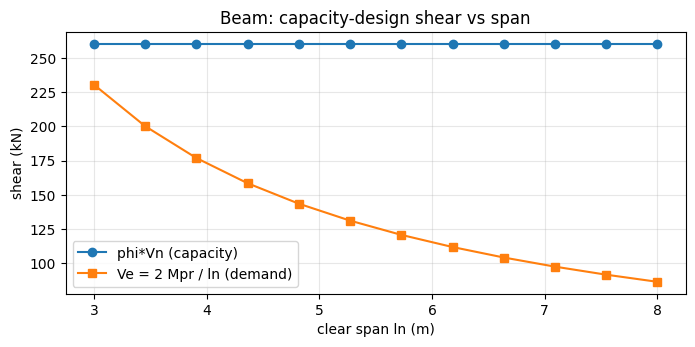

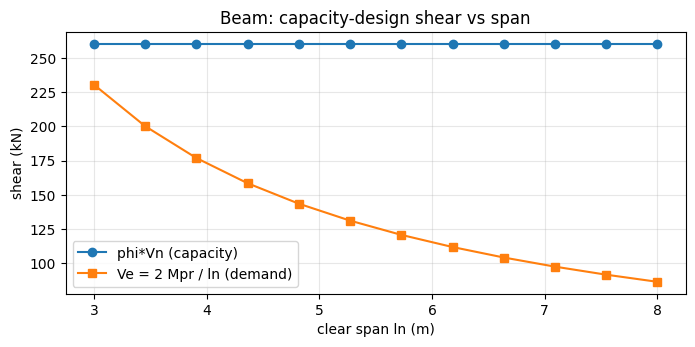

In [2]:
lns = np.linspace(3000, 8000, 12)
phiMn, phiVn, Ve = [], [], []
for ln in lns:
    b = make_beam(ln)
    cap = b.capacity()
    phiMn.append(cap.phi_Mn_pos); phiVn.append(cap.phi_Vn)
    Ve.append(2 * (cap.Mpr_pos or 0) / (ln/1000))   # kN
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(lns/1000, phiVn, "o-", label="phi*Vn (capacity)")
ax.plot(lns/1000, Ve, "s-", label="Ve = 2 Mpr / ln (demand)")
ax.set_xlabel("clear span ln (m)"); ax.set_ylabel("shear (kN)")
ax.set_title("Beam: capacity-design shear vs span"); ax.legend(); ax.grid(alpha=.3)
fig

## Sweep 2 — wall length vs flexural & shear capacity

Now the wall length `lw`. Both the flexural capacity (`max phi*Mn`) and the shear capacity grow strongly with `lw` — the lever arm and the web area both increase.

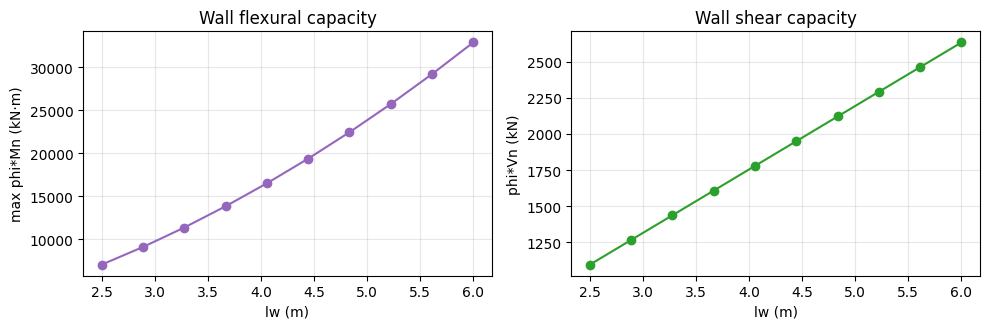

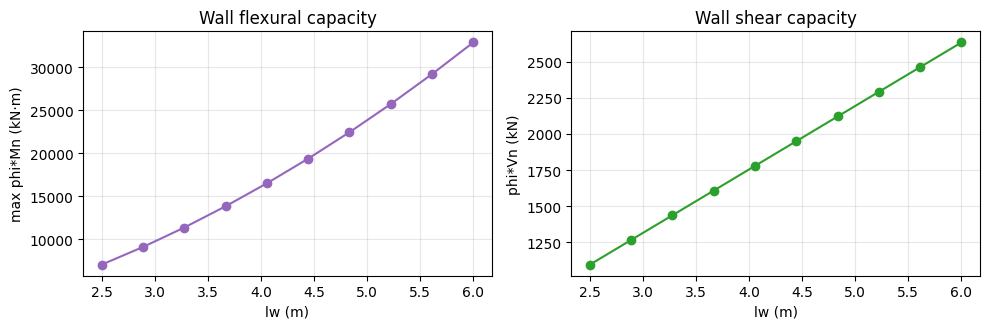

In [3]:
def make_wall(lw):
    return Wall.rectangular(lw=lw, tw=300, hw=15000, lu=3000,
        concrete=concrete, steel=steel, n_y_web=10, db_web=12, cover=25,
        be_top_length=500, be_bot_length=500, n_x_be=3, n_y_be=4, db_be=22,
        db_stirrup=10, seismic=True, rho_t=0.0025, rho_l=0.0025).run()

lws = np.linspace(2500, 6000, 10)
maxMn, phiVn_w = [], []
for lw in lws:
    w = make_wall(lw)
    maxMn.append(float(max(w.surface[0.0].phi_Mn)))
    phiVn_w.append(w.phi_Vn)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.4))
a1.plot(lws/1000, maxMn, "o-", color="tab:purple"); a1.set_xlabel("lw (m)")
a1.set_ylabel("max phi*Mn (kN·m)"); a1.set_title("Wall flexural capacity"); a1.grid(alpha=.3)
a2.plot(lws/1000, phiVn_w, "o-", color="tab:green"); a2.set_xlabel("lw (m)")
a2.set_ylabel("phi*Vn (kN)"); a2.set_title("Wall shear capacity"); a2.grid(alpha=.3)
fig.tight_layout(); fig

## Optimization — rank detailing alternatives by steel weight

`run_optimize` builds the design baseline, then sweeps bar/leg combinations and ranks them by `kg/m³` of concrete. Here are the lightest feasible beams.

In [4]:
beam = make_beam(5500)
demands = beam.demands(Mu_pos_i=90, Mu_neg_i=180, Vu_i=220,
                       Mu_pos_mid=210, Mu_neg_mid=45, Vu_mid=90,
                       Mu_pos_j=90, Mu_neg_j=180, Vu_j=220)
alts = beam_optimize(beam, demands)
print(f"{len(alts)} alternatives explored. Top 5 by steel weight:\n")
print(f"{'#':>2}  {'top':>10}  {'bot':>10}  {'stirrup':>12}  {'kg/m3':>7}  feasible")
for i, a in enumerate(alts[:5]):
    print(f"{i:>2}  {a.n_top}phi{a.db_top:>2.0f}{'':>4}  {a.n_bot}phi{a.db_bot:>2.0f}{'':>4}  "
          f"{a.n_legs}L phi{a.db_stirrup:>2.0f} {'':>3}  {a.rho_total:>7.1f}  {a.feasible}")

442 alternatives explored. Top 5 by steel weight:

 #         top         bot       stirrup    kg/m3  feasible
 0  5phi12      5phi12      2L phi10        107.5  True
 1  5phi12      3phi16      2L phi10        109.3  True
 2  3phi16      5phi12      2L phi10        109.3  True
 3  5phi12      2phi20      2L phi10        110.5  True
 4  2phi20      5phi12      2L phi10        110.5  True


---
**Takeaway.** Elements are disposable objects: wrap any factory in a loop to explore a design space, and let `run_optimize` rank the detailing for you.